# Optimal Control for IFFLs (Fold-Change Detector): Maximizing Peak $B(t)$

## Problem Formulation

In the dimensionless IFFL system:
$$\dot{A} = \tau_r(r)\,r\,(u - A), \qquad A(0) = 1$$
$$\dot{B} = \tau_r(r)\left(\frac{u}{A} - B\right), \qquad B(0) = 1$$
where $u(t) \in [u_{\min}, u_{\max}]$ and $\tau_r(r) = \frac{1}{\min(r, 1)}$. We want to maximize the highest peak $\max_{t \in [0, T]} B(t)$.

### Reduction to a terminal-cost problem

The initial state $(A, B) = (1, 1)$ is the steady state for $u = 1$, and we assume $u_{\min} \le 1 \le u_{\max}$. Holding $u = 1$ therefore keeps the system at rest. Any control that reaches a peak $B(t^*)$ at $t^* < T$ can be preceded by $T - t^*$ of rest at $u = 1$, so the same value is reached at $t = T$. Hence
$$\max_{u}\ \max_{t \in [0, T]} B(t) = \max_{u}\ B(T),$$
and we solve, using PMP,
$$\min_{u \in [u_{\min}, u_{\max}]} \; -B(T).$$
This is exact, unlike an $L^p$ proxy $\frac{1}{p}\int_0^T B^p\,dt$. The proxy rewards time spent at high $B$, not just the height of the peak, so its optimum is not the max-peak control.

### Pontryagin's Maximum Principle (PMP)

The Hamiltonian is:
$$H(A, B, u, \lambda) = \lambda_1 \tau_r(r)\,r\,(u - A) + \lambda_2 \tau_r(r)\left(\frac{u}{A} - B\right)$$

**Optimal Bang-Bang Control Law:**
$$\sigma(t) = r\lambda_1 + \frac{\lambda_2}{A}$$
$$u^*(t) = \begin{cases} u_{\max} & \text{if } \sigma(t) < 0 \\ u_{\min} & \text{if } \sigma(t) > 0 \end{cases}$$

**Costate Equations** (terminal conditions from $\lambda(T) = \partial(-B(T))/\partial(A, B)$):
$$\dot{\lambda}_1 = -\frac{\partial H}{\partial A} = \tau_r(r)\left(r\lambda_1 + \frac{u}{A^2}\lambda_2\right), \qquad \lambda_1(T) = 0$$
$$\dot{\lambda}_2 = -\frac{\partial H}{\partial B} = \tau_r(r)\lambda_2, \qquad \lambda_2(T) = -1 \quad\Rightarrow\quad \lambda_2(t) = -e^{-\tau_r(r)(T - t)}$$

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.optimize import OptimizeResult as OdeResult

In [11]:
# Control bounds (umax > 1 allows positive fold-change overshoot in B)
umin = 0.5
umax = 2.0
# u = 1 must be admissible: resting at (A, B) = (1, 1) is what makes max_t B(t) = max B(T)
assert umin <= 1.0 <= umax

r_values = [0.01, 0.1, 1, 10, 100]

A0 = 1.0
B0 = 1.0
# lambda(T) = d(-B(T)) / d(A, B)
lambda_T = [0.0, -1.0]

In [12]:
def t_relax(r):
    return 1.0 / min(r, 1.0)

def get_grid_n(r, tmax):
    # resolve the fast variable: its time constant is 1/max(r, 1/r)
    return max(int(20 * max(r, 1.0 / r) * tmax) + 1, 2000)

def sweep_state(t, u, r):
    tr = t_relax(r)
    a = tr * r
    A = np.empty_like(t)
    B = np.empty_like(t)
    Ak, Bk = float(A0), float(B0)
    A[0], B[0] = Ak, Bk
    tl, ul = t.tolist(), u.tolist()
    for k in range(len(t) - 1):
        h = tl[k + 1] - tl[k]
        u0, u1 = ul[k], ul[k + 1]
        um = 0.5 * (u0 + u1)
        k1a = a * (u0 - Ak);  k1b = tr * (u0 / Ak - Bk)
        Aa, Ba = Ak + 0.5 * h * k1a, Bk + 0.5 * h * k1b
        k2a = a * (um - Aa);  k2b = tr * (um / Aa - Ba)
        Aa, Ba = Ak + 0.5 * h * k2a, Bk + 0.5 * h * k2b
        k3a = a * (um - Aa);  k3b = tr * (um / Aa - Ba)
        Aa, Ba = Ak + h * k3a, Bk + h * k3b
        k4a = a * (u1 - Aa);  k4b = tr * (u1 / Aa - Ba)
        Ak += h / 6.0 * (k1a + 2 * k2a + 2 * k3a + k4a)
        Bk += h / 6.0 * (k1b + 2 * k2b + 2 * k3b + k4b)
        A[k + 1], B[k + 1] = Ak, Bk
    return A, B

def sweep_costate_B_T(t, u, A, r):
    """Backward RK4 sweep for costates of min -B(T) (no running cost, so B does not enter)."""
    tr = t_relax(r)
    a = tr * r
    n = len(t)
    Am = 0.5 * (A[1:] + A[:-1])
    um = 0.5 * (u[1:] + u[:-1])

    c = (tr * u / A**2).tolist()
    cm = (tr * um / Am**2).tolist()

    tl = t.tolist()
    L1 = np.empty(n)
    L2 = np.empty(n)
    l1, l2 = map(float, lambda_T)
    L1[-1], L2[-1] = l1, l2

    for k in range(n - 1, 0, -1):
        h = tl[k - 1] - tl[k]
        k1a = a * l1 + c[k] * l2;        k1b = tr * l2
        x1, x2 = l1 + 0.5 * h * k1a, l2 + 0.5 * h * k1b
        k2a = a * x1 + cm[k - 1] * x2;   k2b = tr * x2
        x1, x2 = l1 + 0.5 * h * k2a, l2 + 0.5 * h * k2b
        k3a = a * x1 + cm[k - 1] * x2;   k3b = tr * x2
        x1, x2 = l1 + h * k3a, l2 + h * k3b
        k4a = a * x1 + c[k - 1] * x2;    k4b = tr * x2
        l1 += h / 6.0 * (k1a + 2 * k2a + 2 * k3a + k4a)
        l2 += h / 6.0 * (k1b + 2 * k2b + 2 * k3b + k4b)
        L1[k - 1], L2[k - 1] = l1, l2
    return L1, L2

def forward_backward_max_B_T(tmin, tmax, t_grid_n, r, max_iterations=1500,
                             relax=0.05, stable_iters=5):
    t_grid = np.linspace(tmin, tmax, t_grid_n)
    # start from umin (random / umax starts converge to the same switch, just slower)
    u_prev = np.full(t_grid_n, umin)
    last_bb, n_stable, snapped = None, 0, False

    for it in range(max_iterations):
        A, B = sweep_state(t_grid, u_prev, r)
        L1, L2 = sweep_costate_B_T(t_grid, u_prev, A, r)
        sigma = r * L1 + L2 / A
        u_bb = np.where(sigma < 0, umax, umin)

        if snapped:
            bad = np.flatnonzero(u_bb != u_prev)
            sw = np.flatnonzero(np.diff(u_prev))
            if len(bad) == 0 or (len(sw) > 0 and np.isin(bad, np.concatenate([sw, sw + 1])).all()):
                print(f'r={r}: converged after {it + 1} iterations')
                break
            snapped = False

        n_stable = n_stable + 1 if last_bb is not None and np.array_equal(u_bb, last_bb) else 0
        last_bb = u_bb
        if n_stable >= stable_iters:
            u_prev, snapped, n_stable = u_bb.astype(float), True, 0
        else:
            u_prev = relax * u_bb + (1.0 - relax) * u_prev
    else:
        # happens when sigma is nearly flat at the switch, so it jitters by a few grid points
        print(f'r={r}: NOT converged after {max_iterations} iterations (using last bang-bang)')

    u = np.where(u_prev > 0.5 * (umax + umin), umax, umin)
    A, B = sweep_state(t_grid, u, r)
    L1, L2 = sweep_costate_B_T(t_grid, u, A, r)
    t_switch = t_grid[np.flatnonzero(np.diff(u)) + 1]
    return OdeResult(t=t_grid, y=np.vstack([A, B, L1, L2]), u=u,
                     peak_B=np.max(B), B_T=B[-1], t_switch=t_switch)

def get_constant_max_solution(tmin, tmax, t_grid, r):
    """Constant u = umax step response from (A0=1, B0=1)."""
    u_const = np.full_like(t_grid, umax)
    A, B = sweep_state(t_grid, u_const, r)
    return OdeResult(t=t_grid, y=np.vstack([A, B]), u=u_const, peak_B=np.max(B))

r=0.01: converged after 41 iterations


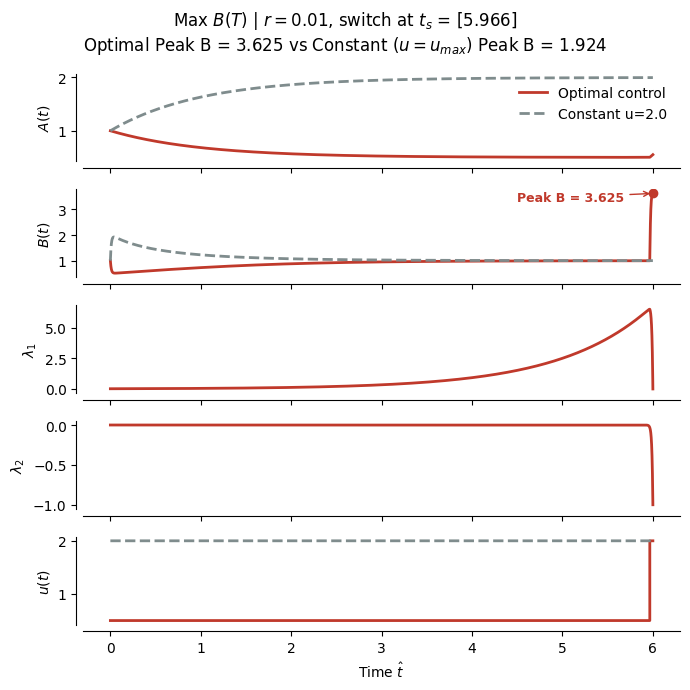

r=0.1: converged after 43 iterations


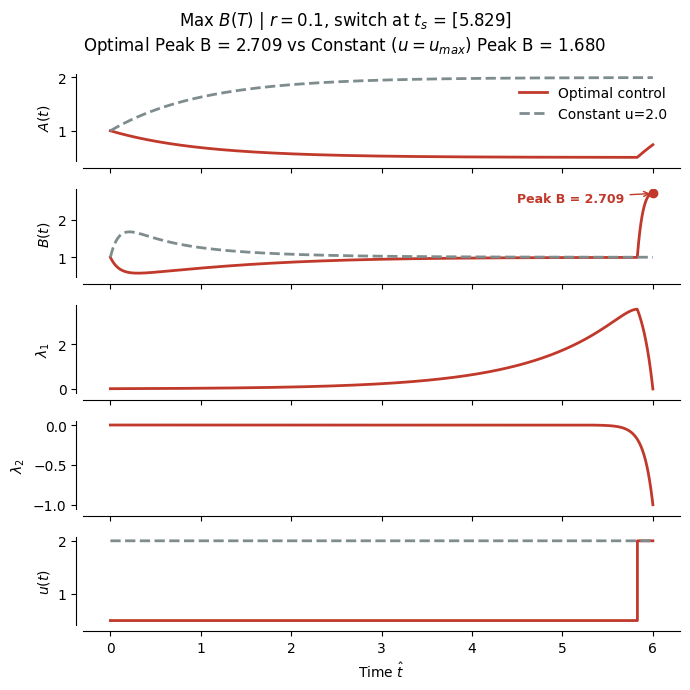

r=1: converged after 74 iterations


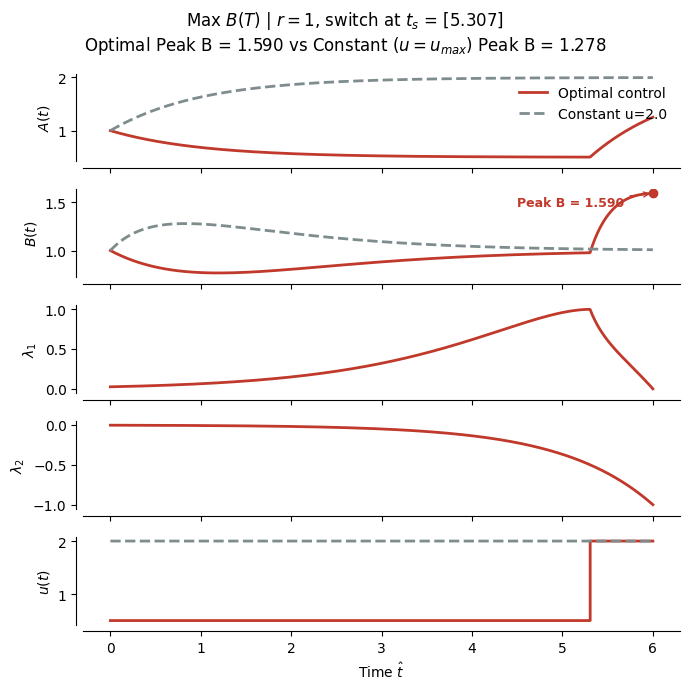

r=10: converged after 32 iterations


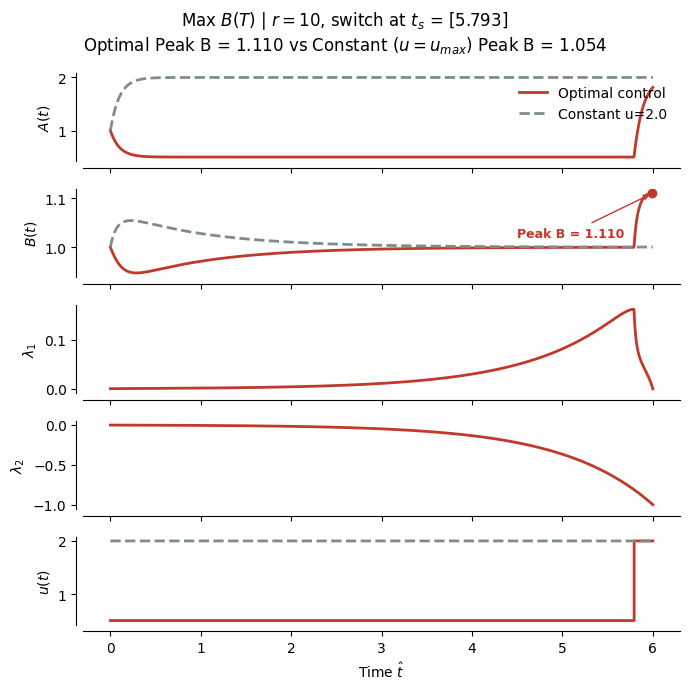

r=100: NOT converged after 1500 iterations (using last bang-bang)


/tmp/ipykernel_1117491/2323753222.py:52: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


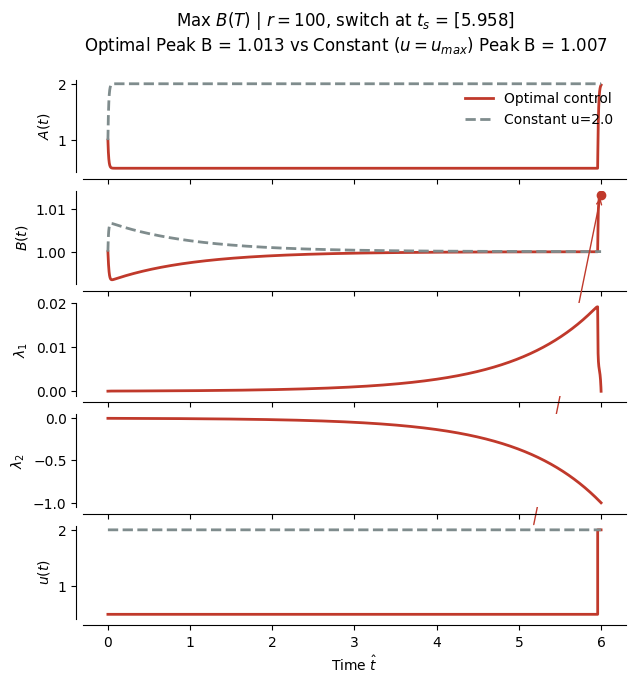

,r,Optimal Peak B,Constant (u=umax) Peak B,Gain (%)
0,0.01,3.624999,1.924166,88.393228
1,0.10,2.708550,1.680385,61.186285
2,1.00,1.589607,1.278465,24.337167
3,10.00,1.110222,1.054467,5.287501
4,100.00,1.013258,1.006627,0.658673


In [13]:
def plot_peak_solution(sol, const_sol, r):
    t = sol.t
    As, Bs, L1s, L2s = sol.y
    us = sol.u

    As_c, Bs_c = const_sol.y
    us_c = const_sol.u

    fig, axs = plt.subplots(nrows=5, ncols=1, figsize=(7, 7), sharex=True)
    lw = 2
    opt_color = '#C0392B'
    const_color = '#7F8C8D'

    # State A
    axs[0].plot(t, As, lw=lw, color=opt_color, label='Optimal control')
    axs[0].plot(t, As_c, lw=lw, linestyle='--', color=const_color, label=f'Constant u={umax}')
    axs[0].set_ylabel('$A(t)$')
    axs[0].legend(frameon=False, loc='upper right')

    # State B (Highlight Peak)
    axs[1].plot(t, Bs, lw=lw, color=opt_color)
    axs[1].plot(t, Bs_c, lw=lw, linestyle='--', color=const_color)
    peak_idx = np.argmax(Bs)
    axs[1].scatter([t[peak_idx]], [Bs[peak_idx]], color=opt_color, zorder=5)
    axs[1].annotate(f'Peak B = {Bs[peak_idx]:.3f}',
                    xy=(t[peak_idx], Bs[peak_idx]),
                    xytext=(max(0, t[peak_idx] - 1.5), Bs[peak_idx] * 0.92),
                    arrowprops=dict(arrowstyle='->', color=opt_color),
                    fontsize=9, fontweight='bold', color=opt_color)
    axs[1].set_ylabel('$B(t)$')

    # Costates
    axs[2].plot(t, L1s, lw=lw, color=opt_color)
    axs[2].set_ylabel('$\\lambda_1$')

    axs[3].plot(t, L2s, lw=lw, color=opt_color)
    axs[3].set_ylabel('$\\lambda_2$')

    # Control u
    axs[4].step(t, us, where='post', lw=lw, color=opt_color)
    axs[4].plot(t, us_c, lw=lw, linestyle='--', color=const_color)
    axs[4].set_ylabel('$u(t)$')
    axs[4].set_xlabel('Time $\\hat{t}$')

    for ax in axs:
        sns.despine(ax=ax)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))

    fig.suptitle(f'Max $B(T)$ | $r = {r}$, switch at $t_s$ = {np.round(sol.t_switch, 3)}\n'
                 f'Optimal Peak B = {sol.peak_B:.3f} vs Constant ($u=u_{{max}}$) Peak B = {const_sol.peak_B:.3f}')
    plt.tight_layout()
    plt.show()


# Run across all r values
tmin, tmax = 0.0, 6.0
summary = []
opt_sols = {}

for r in r_values:
    opt_sol = forward_backward_max_B_T(tmin, tmax, get_grid_n(r, tmax), r=r)
    opt_sols[r] = opt_sol
    const_sol = get_constant_max_solution(tmin, tmax, opt_sol.t, r=r)
    summary.append({
        'r': r,
        'Optimal Peak B': opt_sol.peak_B,
        'Constant (u=umax) Peak B': const_sol.peak_B,
        'Gain (%)': 100.0 * (opt_sol.peak_B - const_sol.peak_B) / const_sol.peak_B
    })
    plot_peak_solution(opt_sol, const_sol, r=r)

display(pd.DataFrame(summary))